In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector

db = mysql.connector.connect(
    host='localhost',
    user='root',
    password='Sql.1234',
    database='ecommerce'
)
cur=db.cursor()

# List all unique cities where customers are located

In [2]:
query= """ 
select distinct customer_city 
from customers"""
cur.execute(query)
data=cur.fetchall()
df = pd.DataFrame(data, columns=['customer_city'])
df

,customer_city
0,franca
1,sao bernardo do campo
2,sao paulo
3,mogi das cruzes
4,campinas
...,...
4114,siriji
4115,natividade da serra
4116,monte bonito
4117,sao rafael


# Count the number of orders placed in 2017

In [9]:
query= """ 
select count(order_id) 
from orders 
where year(order_purchase_timestamp)=2017 """

#built in function year() in SQL returns the year
data = [(15000,)]

print(data[0])     
print(data[0][0])  

cur.execute(query)
data=cur.fetchall()
"total orders placed in 2017 are" ,data[0][0] # extract the first row and the first column

(15000,)
15000


('total orders placed in 2017 are', 45101)

# Find total sales per category

In [11]:
#need to join order_items on products to obtain category and sum to obtain total sales

query = """
SELECT
    LOWER(p.product_category_name) AS category,
    ROUND(SUM(oi.price), 2) AS sales
FROM products AS p
JOIN order_items AS oi 
    ON p.product_id = oi.product_id
GROUP BY category
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(data, columns=["Category", "Sales"])
df

,Category,Sales
0,beleza_saude,1258681.34
1,esporte_lazer,988048.97
2,cool_stuff,635290.85
3,informatica_acessorios,911954.32
4,relogios_presentes,1205005.68
...,...,...
69,flores,1110.04
70,portateis_cozinha_e_preparadores_de_alimentos,3968.53
71,casa_conforto_2,760.27
72,moveis_colchao_e_estofado,4368.08


 # Calculate the percentage of orders that were paid in installments

In [12]:
query=""" 
select (
sum(case when payment_installments >= 1 then 1 else 0 end))/count(*)*100 from payments
"""
cur.execute(query)
data=cur.fetchall()
"the total percentage of order placed in installments are", data[0][0]

('the total percentage of order placed in installments are',
 Decimal('99.9981'))

# Count the number of customers from each state 

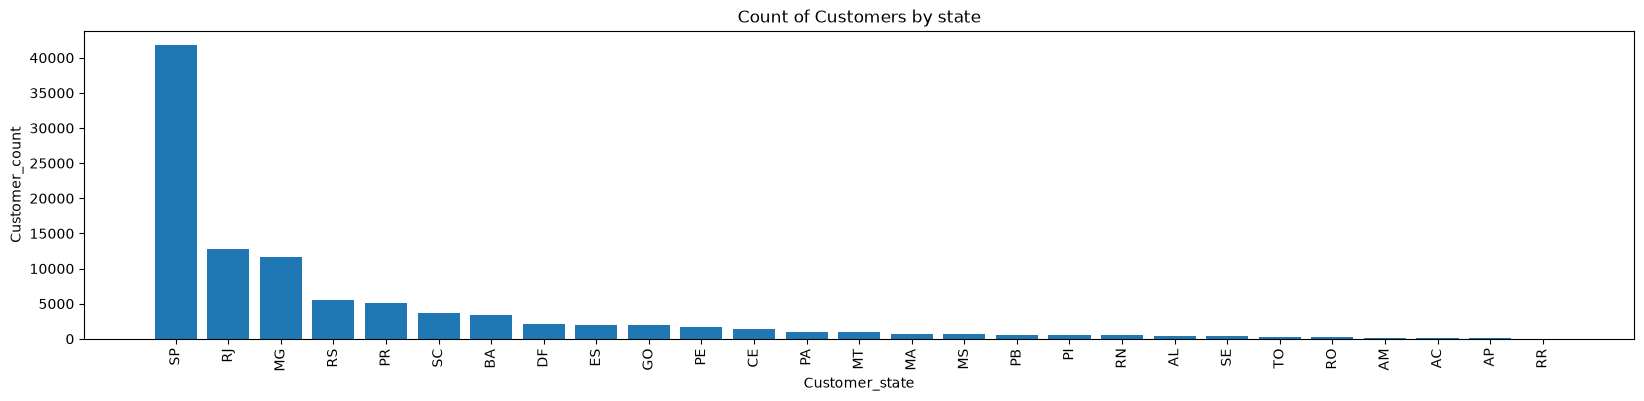

In [13]:
query=""" 
select customer_state,count(customer_id) 
from customers 
group by customer_state
"""
cur.execute(query)
data=cur.fetchall() 
df=pd.DataFrame(data, columns=["Customer_state","Customer_count"])
df=df.sort_values(by="Customer_count", ascending= False)
plt.figure(figsize=(20,4))
plt.bar(df["Customer_state"],df["Customer_count"])
plt.xticks(rotation=90)
plt.xlabel("Customer_state")
plt.ylabel("Customer_count")
plt.title("Count of Customers by state")
plt.show()

# Calculate number of orders per month in 2018

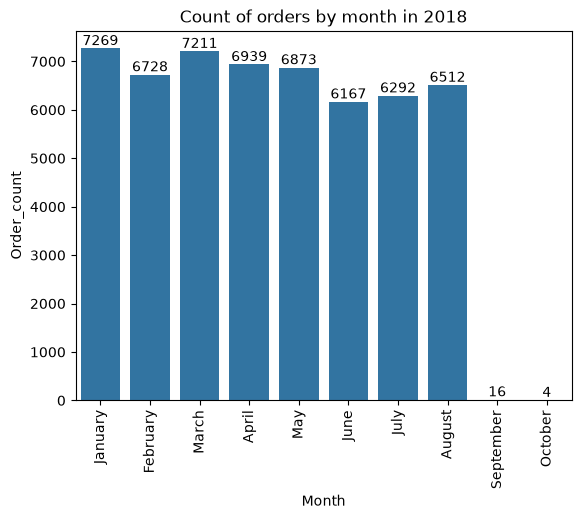

In [14]:
query=""" 
select monthname(order_purchase_timestamp) month,count(order_id) order_count 
from orders
where year(order_purchase_timestamp)=2018 
group by month
"""
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data, columns=["Month","Order_count"])
df
o=["January", "February" ,"March", "April", "May","June", "July", "August", "September", "October"]
labeldata=sns.barplot(x= df["Month"],y= df["Order_count"], data=df, order=o)
plt.xticks(rotation=90)
labeldata.bar_label(labeldata.containers[0])
plt.title("Count of orders by month in 2018")
plt.show()

# Find the average number of orders per product, grouped by customer city in descending order of average orders

In [16]:
query = """
SELECT
    c.customer_city,
    ROUND(AVG(order_counts.item_count), 2) AS average_items_per_order
FROM customers AS c
JOIN (
    SELECT
        o.order_id,
        o.customer_id,
        COUNT(oi.order_id) AS item_count
    FROM orders AS o
    JOIN order_items AS oi
        ON o.order_id = oi.order_id
    GROUP BY o.order_id, o.customer_id
) AS order_counts
    ON c.customer_id = order_counts.customer_id
GROUP BY c.customer_city
ORDER BY average_items_per_order DESC;
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(
    data,
    columns=["Customer_city", "Average_items_per_order"]
)
df

,Customer_city,Average_items_per_order
0,padre carvalho,7.00
1,celso ramos,6.50
2,datas,6.00
3,candido godoi,6.00
4,matias olimpio,5.00
...,...,...
4105,lagoa da canoa,1.00
4106,japaratuba,1.00
4107,sebastiao leal,1.00
4108,morro agudo de goias,1.00


# Calculate percentage of total revenue contributed by each product category

In [17]:
query = """
SELECT
    LOWER(p.product_category_name) AS category,
    ROUND(SUM(oi.price) * 100.0 /(SELECT SUM(price) FROM order_items),2) AS sales_percent
FROM products AS p
JOIN order_items AS oi
    ON p.product_id = oi.product_id
GROUP BY LOWER(p.product_category_name)
ORDER BY sales_percent DESC;
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(data, columns=["Category", "Sales_percent"])
df

,Category,Sales_percent
0,beleza_saude,9.26
1,relogios_presentes,8.87
2,cama_mesa_banho,7.63
3,esporte_lazer,7.27
4,informatica_acessorios,6.71
...,...,...
69,flores,0.01
70,casa_conforto_2,0.01
71,cds_dvds_musicais,0.01
72,fashion_roupa_infanto_juvenil,0.00


# Identify correlation between product price and the number of times a product has been purchased

In [23]:
import numpy as np
import pandas as pd

query = """
SELECT
    products.product_id,
    COUNT(order_items.product_id) AS purchase_count,
    ROUND(AVG(order_items.price), 2) AS average_price
FROM products
JOIN order_items
    ON products.product_id = order_items.product_id
GROUP BY products.product_id
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(data, columns=["Product_id", "Count", "Sales_average"])

array1 = df["Count"]
array2 = df["Sales_average"]

cor = np.corrcoef(array1, array2)
corr = round(cor[0][1], 2)

print("Correlation between product price and purchase count:", corr)

if corr >= 0.5:
    print("There is positive correlation")
elif corr <= -0.5:
    print("There is negative correlation")
else:
    print("There is weak or no linear correlation")

Correlation between product price and purchase count: -0.03
There is weak or no linear correlation


# Calculate total revenue generated by each seller, and rank them by revenue

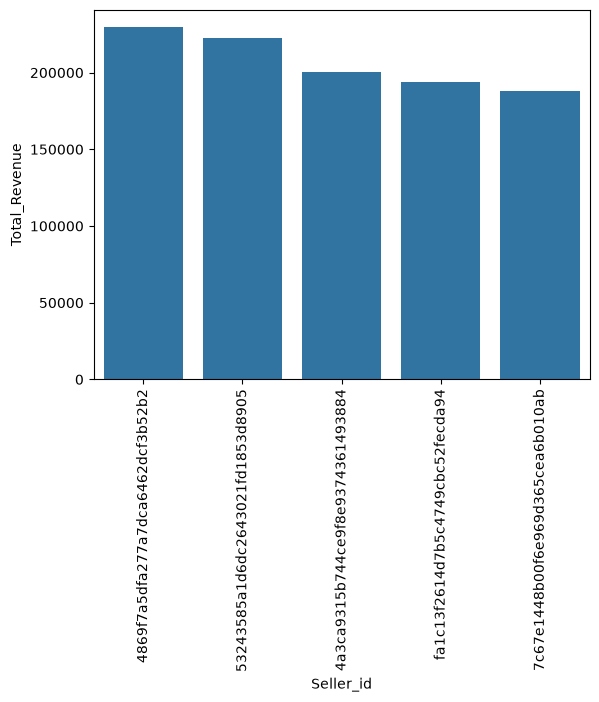

In [25]:
query = """
SELECT
    seller_id,
    total_revenue,
    DENSE_RANK() OVER (ORDER BY total_revenue DESC) AS rank_revenue
FROM (
    SELECT
        seller_id,
        SUM(price) AS total_revenue
    FROM order_items
    GROUP BY seller_id
) AS tab
ORDER BY rank_revenue
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(
    data,
    columns=["Seller_id", "Total_Revenue", "Rank"]
)

df.head()

sns.barplot(
    x="Seller_id",
    y="Total_Revenue",
    data=df.head()
)

plt.xticks(rotation=90)
plt.show()

# Calculate moving average of order values for each customer over their order history

In [29]:
query = """
SELECT
    customer_id,
    order_purchase_timestamp,
    payment,
    ROUND(
        AVG(payment) OVER (
            PARTITION BY customer_id
            ORDER BY order_purchase_timestamp
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ),
        2
    ) AS moving_average
FROM (
    SELECT
        o.customer_id,
        o.order_id,
        o.order_purchase_timestamp,
        SUM(p.payment_value) AS payment
    FROM orders AS o
    JOIN payments AS p
        ON o.order_id = p.order_id
    GROUP BY
        o.customer_id,
        o.order_id,
        o.order_purchase_timestamp
) AS a
ORDER BY customer_id, order_purchase_timestamp
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(
    data,
    columns=[
        "Customer_id",
        "order_purchase_timestamp",
        "payment",
        "moving_average"
    ]
)

df.head()

,Customer_id,order_purchase_timestamp,payment,moving_average
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,114.739998,114.74
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,67.410004,67.41
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,195.419998,195.42
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,179.350006,179.35
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,107.010002,107.01


# Calculate cumulative sales per month for each year

In [3]:
query = """
SELECT
    years, month, payment,
    ROUND(SUM(payment) OVER (PARTITION BY years ORDER BY month), 2) AS cumulative_sales
FROM (
    SELECT YEAR(o.order_purchase_timestamp) AS years, MONTH(o.order_purchase_timestamp) AS month, SUM(p.payment_value) AS payment
    FROM orders AS o
    JOIN payments AS p
        ON o.order_id = p.order_id
    GROUP BY
        YEAR(o.order_purchase_timestamp), MONTH(o.order_purchase_timestamp)
) AS a 
ORDER BY years, month
"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(
    data,
    columns=["Year", "Month", "Monthly_Sales", "Cumulative_Sales"]
)

df.head()


,Year,Month,Monthly_Sales,Cumulative_Sales
0,2016,9,252.239994,252.24
1,2016,10,59090.479999,59342.72
2,2016,12,19.620001,59362.34
3,2017,1,138488.040064,138488.04
4,2017,2,291908.009507,430396.05
